# 딥러닝의 이해 과제2

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 난수 고정
tf.keras.utils.set_random_seed(42)

# 데이터 불러오기
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# 정규화
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = [
    "T-shirt/top", "Trouser", "Pullover",
    "Dress", "Coat", "Sandal", "Shirt",
    "Sneaker", "Bag", "Ankle boot"
]

print("Train:", x_train.shape)
print("Test:", x_test.shape)
print("Train range:", x_train.min(), x_train.max())
print("Test range:", x_test.min(), x_test.max())



Train: (60000, 28, 28)
Test: (10000, 28, 28)
Train range: 0.0 1.0
Test range: 0.0 1.0


### #1. 1) DNN 모델 학습 및 분류 결과

In [ ]:
# DNN Residual Block
def dnn_residual_block(x, units):
    shortcut = x

    y = layers.Dense(units, use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)

    y = layers.Dense(units, use_bias=False)(y)
    y = layers.BatchNormalization()(y)

    y = layers.Add()([shortcut, y])
    y = layers.Activation("relu")(y)

    return y

# DNN 모델 생성
inputs = layers.Input(shape=(32, 32, 3))

x = layers.Flatten()(inputs)
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = dnn_residual_block(x, 256)
x = dnn_residual_block(x, 256)

outputs = layers.Dense(10, activation="softmax")(x)

dnn_model = models.Model(inputs, outputs)

# 컴파일
dnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 모델 구조 확인
dnn_model.summary()

# 학습
history_dnn = dnn_model.fit(
    x_train, y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# 테스트 데이터 평가
dnn_loss, dnn_acc = dnn_model.evaluate(
    x_test, y_test, verbose=0
)

# 분류 예측
dnn_prob = dnn_model.predict(x_test)
dnn_pred = np.argmax(dnn_prob, axis=1)

print("\n===== DNN Results =====")
print("Test Loss:", dnn_loss)
print("Test Accuracy:", dnn_acc)

print("\nClassification Report:")
print(classification_report(
    y_test, dnn_pred,
    target_names=class_names
))

Fashion-MNIST 데이터를 정규화한 후, 두 개의 은닉층(256개, 128개)으로 구성된 DNN 모델을 학습하였다. 활성화 함수는 ReLU와 Softmax, 최적화 알고리즘은 Adam을 사용하였으며, 15 epochs로 학습하였다.

테스트 결과 정확도는 86.99%, 손실함수는 0.3947, Macro F1-score는 0.87로 나타났다. Trouser의 F1-score가 0.98로 가장 높았고, Shirt는 0.67로 가장 낮아 비슷한 형태의 의류를 구분하는 데 어려움이 있었다. 또한 학습 후반부에 검증 손실함수가 증가하여 과적합 가능성이 나타났다.

### #1. 2) CNN 모델 학습 및 분류 결과

In [ ]:
# CNN 입력 형태 변경
x_train_cnn = x_train[..., np.newaxis]
x_test_cnn = x_test[..., np.newaxis]

# CNN 모델 생성
cnn_model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# 컴파일
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 모델 구조
cnn_model.summary()

# 학습
history_cnn = cnn_model.fit(
    x_train_cnn, y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# 테스트 데이터 평가
cnn_loss, cnn_acc = cnn_model.evaluate(
    x_test_cnn, y_test, verbose=0
)

# 분류 예측
cnn_prob = cnn_model.predict(x_test_cnn)
cnn_pred = np.argmax(cnn_prob, axis=1)

print("\n===== CNN Results =====")
print("Test Loss:", cnn_loss)
print("Test Accuracy:", cnn_acc)

print("\nClassification Report:")
print(classification_report(
    y_test, cnn_pred,
    target_names=class_names
))


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 75s 191ms/step - accuracy: 0.8205 - loss: 0.5044 - val_accuracy: 0.8804 - val_loss: 0.3438
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 92s 217ms/step - accuracy: 0.8879 - loss: 0.3158 - val_accuracy: 0.8947 - val_loss: 0.2995
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 60s 160ms/step - accuracy: 0.9024 - loss: 0.2737 - val_accuracy: 0.9003 - val_loss: 0.2735
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 85s 170ms/step - accuracy: 0.9115 - loss: 0.2453 - val_accuracy: 0.9079 - val_loss: 0.2518
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 101s 220ms/step - accuracy: 0.9195 - loss: 0.2222 - val_accuracy: 0.9095 - val_loss: 0.2448
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 71s 188ms/step - accuracy: 0.9252 - loss: 0.2031 - val_accuracy: 0.9106 - val_loss: 0.2398
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 57s 153ms/step - accuracy: 0.9326 - loss: 0.1852 - val_accuracy: 0.9115 - val_loss: 0.2371
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 81s 151ms/step - accuracy: 0.9398 - loss: 

Fashion-MNIST 데이터를 (28, 28, 1) 형태로 변환한 후, 두 개의 합성곱층(32개, 64개 필터)과 최대 풀링층, 완전연결층으로 구성된 CNN 모델을 학습하였다. 활성화 함수는 ReLU와 Softmax, 최적화 알고리즘은 Adam을 사용하였으며, 15 epochs로 학습하였다.

테스트 결과 정확도는 89.09%, 손실함수는 0.3889, Macro F1-score는 0.89로 나타났다. Trouser의 F1-score가 0.99로 가장 높았고, Shirt는 0.72로 가장 낮아 비슷한 형태의 의류를 구분하는 데 어려움이 있었다. 또한 학습 후반부에 검증 손실함수가 증가하여 과적합 가능성이 나타났다.

### #1.3) DNN과 CNN 성능 비교 및 분석

===== Model Comparison =====
Model  Test Accuracy  Test Loss  Total Parameters
  DNN         0.8616  72.589172            235146
  CNN         0.8909   0.388930            421642


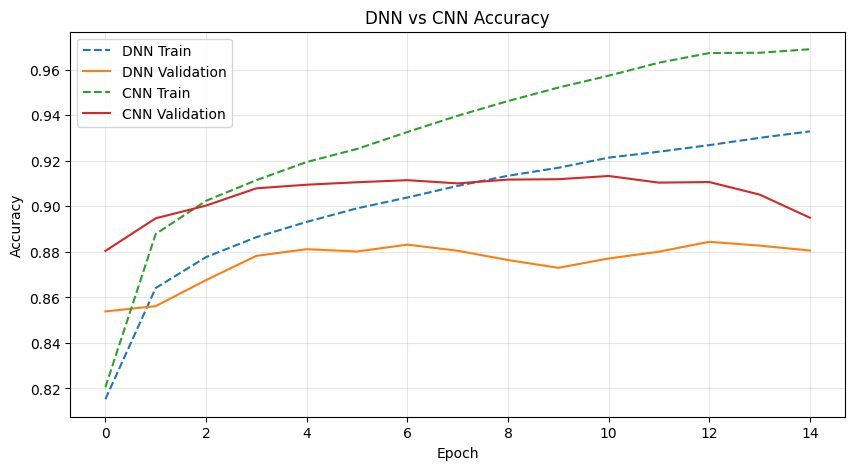

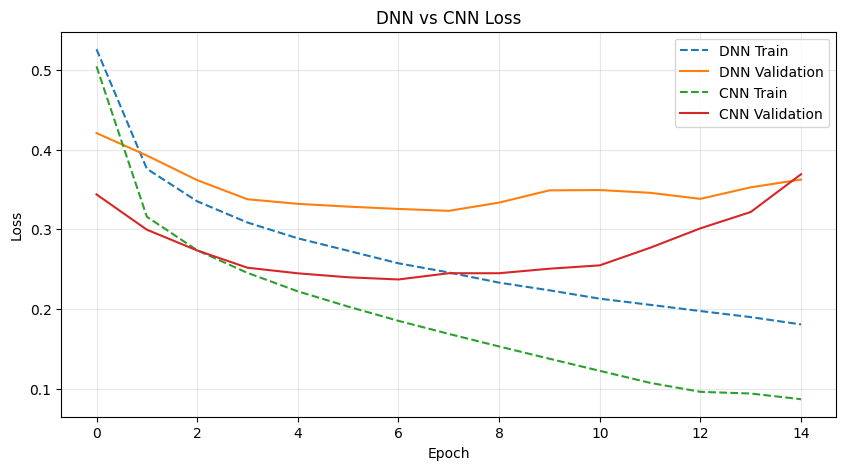

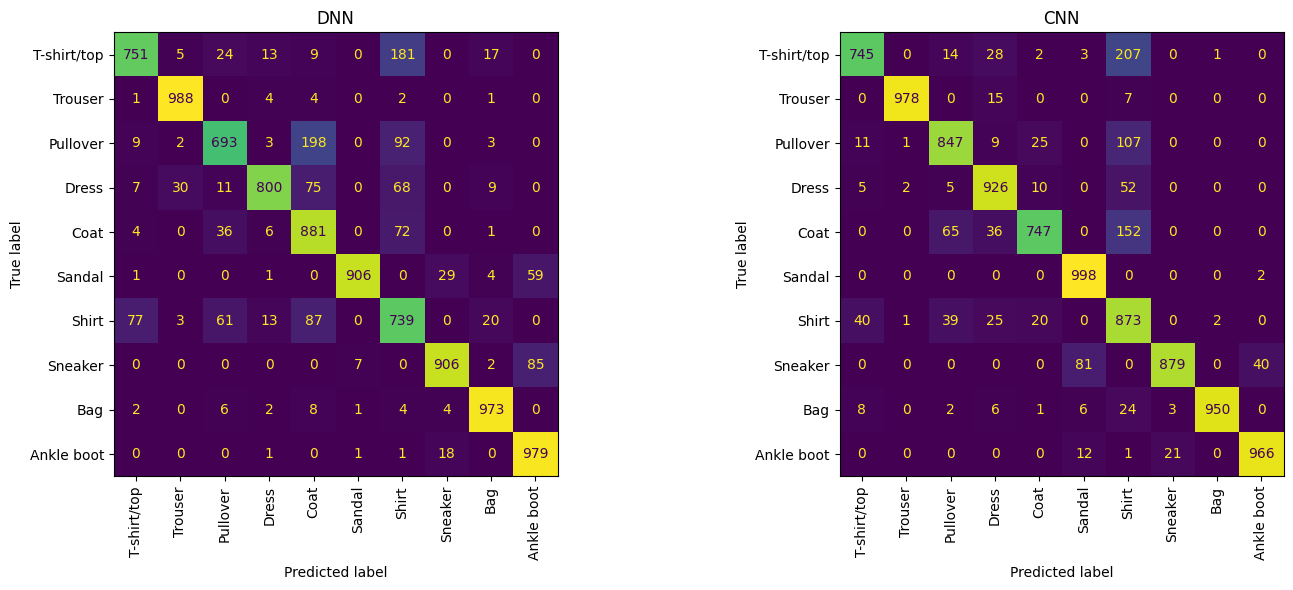

In [ ]:
# 1. 성능 비교표
comparison = pd.DataFrame({
    "Model": ["DNN", "CNN"],
    "Test Accuracy": [dnn_acc, cnn_acc],
    "Test Loss": [dnn_loss, cnn_loss],
    "Total Parameters": [
        dnn_model.count_params(),
        cnn_model.count_params()
    ]
})

print("===== Model Comparison =====")
print(comparison.to_string(index=False))

# 2. 학습 및 검증 정확도 비교
plt.figure(figsize=(10, 5))

plt.plot(
    history_dnn.history["accuracy"],
    label="DNN Train", linestyle="--"
)
plt.plot(
    history_dnn.history["val_accuracy"],
    label="DNN Validation"
)
plt.plot(
    history_cnn.history["accuracy"],
    label="CNN Train", linestyle="--"
)
plt.plot(
    history_cnn.history["val_accuracy"],
    label="CNN Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DNN vs CNN Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 3. 손실함수 비교
plt.figure(figsize=(10, 5))

plt.plot(
    history_dnn.history["loss"],
    label="DNN Train", linestyle="--"
)
plt.plot(
    history_dnn.history["val_loss"],
    label="DNN Validation"
)
plt.plot(
    history_cnn.history["loss"],
    label="CNN Train", linestyle="--"
)
plt.plot(
    history_cnn.history["val_loss"],
    label="CNN Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DNN vs CNN Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 4. 혼동행렬 비교
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, pred, name in zip(
    axes,
    [dnn_pred, cnn_pred],
    ["DNN", "CNN"]
):
    cm = confusion_matrix(y_test, pred)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    ).plot(
        ax=ax,
        xticks_rotation=90,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


CNN의 테스트 정확도는 89.09%로 DNN의 86.99%보다 2.10%p 높게 나타났다. 또한 CNN은 DNN보다 테스트 손실함수가 낮고 Macro F1-score가 높아 전반적으로 우수한 분류 성능을 보였다.

이러한 차이는 모델의 구조적 특성에 기인한 것으로 해석할 수 있다. DNN은 이미지를 일차원 벡터로 변환하여 학습하는 반면, CNN은 합성곱층을 통해 이미지의 공간적 특징을 추출할 수 있기 때문에 이미지 분류에 상대적으로 유리하다.

클래스별 성능에서도 Shirt의 F1-score는 DNN이 0.67, CNN이 0.72로 CNN이 더 높았다. 다만 CNN은 DNN보다 많은 모수를 사용하였으며, 두 모델 모두 학습 후반부에 과적합 경향을 보였다.

따라서 본 실험에서는 CNN이 DNN보다 높은 예측 성능을 보였으며, 이미지 분류 문제에서 CNN의 구조적 장점을 확인할 수 있었다.

### #1.4) DNN과 CNN 전체 모수 개수 계산

In [ ]:
# DNN 각 층의 모수
print("===== DNN Parameters =====")

for layer in dnn_model.layers:
    print(
        layer.name,
        layer.__class__.__name__,
        layer.count_params()
    )

print("DNN Total Parameters:",
      dnn_model.count_params())

# CNN 각 층의 모수
print("\n===== CNN Parameters =====")

for layer in cnn_model.layers:
    print(
        layer.name,
        layer.__class__.__name__,
        layer.count_params()
    )

print("CNN Total Parameters:",
      cnn_model.count_params())

# 직접 계산
dnn_params = (
    (784 + 1) * 256
    + (256 + 1) * 128
    + (128 + 1) * 10
)

cnn_params = (
    (3 * 3 * 1 + 1) * 32
    + (3 * 3 * 32 + 1) * 64
    + (7 * 7 * 64 + 1) * 128
    + (128 + 1) * 10
)

print("\n===== Manual Calculation =====")
print("DNN:", dnn_params)
print("CNN:", cnn_params)

print("DNN calculation correct:",
      dnn_params == dnn_model.count_params())

print("CNN calculation correct:",
      cnn_params == cnn_model.count_params())

===== DNN Parameters =====
flatten Flatten 0
dense Dense 200960
dense_1 Dense 32896
dense_2 Dense 1290
DNN Total Parameters: 235146

===== CNN Parameters =====
conv2d Conv2D 320
max_pooling2d MaxPooling2D 0
conv2d_1 Conv2D 18496
max_pooling2d_1 MaxPooling2D 0
flatten_1 Flatten 0
dense_3 Dense 401536
dense_4 Dense 1290
CNN Total Parameters: 421642

===== Manual Calculation =====
DNN: 235146
CNN: 421642
DNN calculation correct: True
CNN calculation correct: True


(1) DNN 모델

Dense층의 모수 개수는 (입력 뉴런 수 + 1) × 출력 뉴런 수로 계산한다.

Dense(256): (784 + 1) × 256 = 200,960

Dense(128): (256 + 1) × 128 = 32,896

Dense(10): (128 + 1) × 10 = 1,290

전체 모수: 200,960 + 32,896 + 1,290 = 235,146개

(2) CNN 모델

Conv2D층의 모수 개수는 (필터 높이 × 필터 너비 × 입력 채널 수 + 1) × 필터 수로 계산한다.

Conv2D(32): (3 × 3 × 1 + 1) × 32 = 320

Conv2D(64): (3 × 3 × 32 + 1) × 64 = 18,496

Dense(128): (7 × 7 × 64 + 1) × 128 = 401,536

Dense(10): (128 + 1) × 10 = 1,290

전체 모수: 320 + 18,496 + 401,536 + 1,290 = 421,642개

따라서 DNN의 전체 모수는 235,146개, CNN은 421,642개로 CNN이 더 많은 모수를 사용하였다.

In [ ]:
from tensorflow.keras.datasets import fashion_mnist

# Fashion-MNIST 테스트 데이터 다시 불러오기
(_, _), (x_test_fashion, y_test_fashion) = fashion_mnist.load_data()

# 정규화
x_test_fashion = x_test_fashion.astype("float32") / 255.0

# 데이터 형태 확인
print("Fashion-MNIST Test Shape:", x_test_fashion.shape)

# DNN 테스트 성능 재평가
dnn_loss_fashion, dnn_acc_fashion = dnn_model.evaluate(
    x_test_fashion,
    y_test_fashion,
    verbose=0
)

print("DNN Test Loss:", dnn_loss_fashion)
print("DNN Test Accuracy:", dnn_acc_fashion)


Fashion-MNIST Test Shape: (10000, 28, 28)
DNN Test Loss: 0.39472588896751404
DNN Test Accuracy: 0.8698999881744385


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Fashion-MNIST 클래스 이름
fashion_class_names = [
    "T-shirt/top", "Trouser", "Pullover",
    "Dress", "Coat", "Sandal", "Shirt",
    "Sneaker", "Bag", "Ankle boot"
]

# DNN 예측
dnn_prob = dnn_model.predict(x_test_fashion, verbose=0)
dnn_pred = np.argmax(dnn_prob, axis=1)

# 분류 성능
print("===== DNN Classification Report =====")
print(classification_report(
    y_test_fashion,
    dnn_pred,
    target_names=fashion_class_names
))

# 혼동행렬
print("===== DNN Confusion Matrix =====")
print(confusion_matrix(y_test_fashion, dnn_pred))


===== DNN Classification Report =====
              precision    recall  f1-score   support

 T-shirt/top       0.90      0.69      0.78      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.81      0.78      0.79      1000
       Dress       0.89      0.88      0.88      1000
        Coat       0.82      0.76      0.79      1000
      Sandal       0.99      0.93      0.96      1000
       Shirt       0.58      0.80      0.67      1000
     Sneaker       0.92      0.97      0.94      1000
         Bag       0.97      0.96      0.97      1000
  Ankle boot       0.94      0.95      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000

===== DNN Confusion Matrix =====
[[689   1  21  27   3   0 252   0   7   0]
 [  1 978   2  13   2   0   3   0   1   0]
 [  6   0 780  11  97   0 104   0   2   0]
 [  6   9  11 879  20   0  72   0   3   0

Model  Test Accuracy  Test Loss  Total Parameters
  DNN         0.8699   0.394726            235146
  CNN         0.8909   0.388930            421642


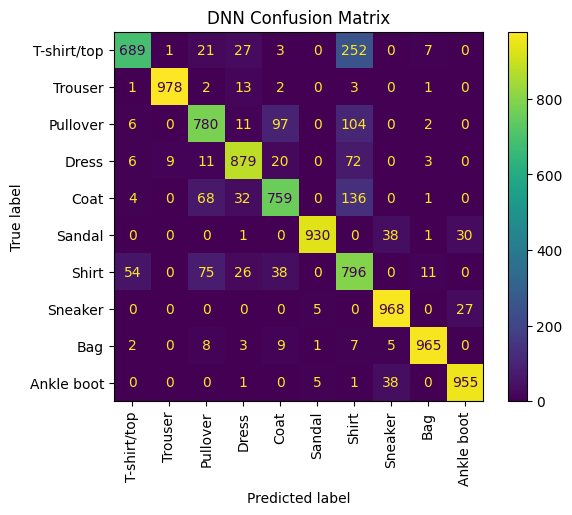

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Fashion-MNIST 테스트 데이터로 DNN 재평가
dnn_loss, dnn_acc = dnn_model.evaluate(
    x_test_fashion, y_test_fashion, verbose=0
)

dnn_pred = np.argmax(
    dnn_model.predict(x_test_fashion, verbose=0),
    axis=1
)

# 성능 비교표 업데이트
comparison = pd.DataFrame({
    "Model": ["DNN", "CNN"],
    "Test Accuracy": [dnn_acc, cnn_acc],
    "Test Loss": [dnn_loss, cnn_loss],
    "Total Parameters": [
        dnn_model.count_params(),
        cnn_model.count_params()
    ]
})

print(comparison.to_string(index=False))

# 최신 DNN 혼동행렬
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test_fashion, dnn_pred),
    display_labels=fashion_class_names
).plot(xticks_rotation=90)

plt.title("DNN Confusion Matrix")
plt.show()

### #2.1) DNN 모델 학습 및 분류 결과

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 난수 고정
tf.keras.utils.set_random_seed(42)

# CIFAR-10 데이터 불러오기
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# 정답 데이터 형태 변경
y_train = y_train.ravel()
y_test = y_test.ravel()

# 정규화
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = [
    "Airplane", "Automobile", "Bird", "Cat",
    "Deer", "Dog", "Frog", "Horse", "Ship", "Truck"
]

print("Train:", x_train.shape)
print("Test:", x_test.shape)
print("Train range:", x_train.min(), x_train.max())
print("Test range:", x_test.min(), x_test.max())


# DNN Residual Block
def dnn_residual_block(x, units):
    shortcut = x

    y = layers.Dense(units, use_bias=False)(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)

    y = layers.Dense(units, use_bias=False)(y)
    y = layers.BatchNormalization()(y)

    y = layers.Add()([shortcut, y])
    y = layers.Activation("relu")(y)

    return y


# DNN 모델 생성
inputs = layers.Input(shape=(32, 32, 3))

x = layers.Flatten()(inputs)
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = dnn_residual_block(x, 256)
x = dnn_residual_block(x, 256)

outputs = layers.Dense(10, activation="softmax")(x)

dnn_model = models.Model(inputs, outputs)

# 컴파일
dnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 모델 구조 확인
dnn_model.summary()

# 학습 (15 → 10 epochs)
history_dnn = dnn_model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# 테스트 데이터 평가
dnn_loss, dnn_acc = dnn_model.evaluate(
    x_test, y_test, verbose=0
)

# 분류 예측
dnn_prob = dnn_model.predict(x_test)
dnn_pred = np.argmax(dnn_prob, axis=1)

print("\n===== DNN Results =====")
print("Test Loss:", dnn_loss)
print("Test Accuracy:", dnn_acc)

print("\nClassification Report:")
print(classification_report(
    y_test, dnn_pred,
    target_names=class_names
))


Train: (50000, 32, 32, 3)
Test: (10000, 32, 32, 3)
Train range: 0.0 1.0
Test range: 0.0 1.0


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_4 (Flatten) │ (None, 3072)      │          0 │ input_layer_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_30 (Dense)    │ (None, 256)       │    786,432 │ flatten_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_30[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_41       │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_31 (Dense)    │ (None, 256)       │     65,536 │ activation_41[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_31[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_42       │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 256)       │     65,536 │ activation_42[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_32[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_17 (Add)        │ (None, 256)       │          0 │ activation_41[0]… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_43       │ (None, 256)       │          0 │ add_17[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_33 (Dense)    │ (None, 256)       │     65,536 │ activation_43[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_33[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_44       │ (None, 256)       │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_34 (Dense)    │ (None, 256)       │     65,536 │ activation_44[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_34[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_18 (Add)        │ (None, 256)       │          0 │ activation_43[0]… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_45       │ (None, 256)       │          0 │ add_18[0][0]    

 Total params: 1,056,266 (4.03 MB)

 Trainable params: 1,053,706 (4.02 MB)

 Non-trainable params: 2,560 (10.00 KB)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.3900 - loss: 1.7442 - val_accuracy: 0.3658 - val_loss: 1.8129
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.4863 - loss: 1.4424 - val_accuracy: 0.3868 - val_loss: 1.7584
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.5371 - loss: 1.3007 - val_accuracy: 0.4096 - val_loss: 1.7151
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5821 - loss: 1.1804 - val_accuracy: 0.3799 - val_loss: 1.8979
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6224 - loss: 1.0721 - val_accuracy: 0.3827 - val_loss: 1.8895
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.6631 - loss: 0.9610 - val_accuracy: 0.3383 - val_loss: 2.1686
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7001 - loss: 0.8600 - val_accuracy: 0.3441 - val_loss: 2.1582
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.7331 - loss: 0.7664 - val_acc

CIFAR-10 데이터에 Batch Normalization과 Residual Block을 적용한 DNN 모델을 학습한 결과, 테스트 정확도는 24.21%, 손실값은 3.5351로 나타났다. Macro F1-score는 0.24로, 전반적인 이미지 분류 성능이 낮음을 확인할 수 있었다.

### #2.2) CNN 모델 학습 및 분류 결과

In [ ]:
# CNN Residual Block
def cnn_residual_block(x, filters, stride=1):
    shortcut = x

    y = layers.Conv2D(
        filters, (3, 3),
        strides=stride,
        padding="same",
        use_bias=False
    )(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation("relu")(y)

    y = layers.Conv2D(
        filters, (3, 3),
        padding="same",
        use_bias=False
    )(y)
    y = layers.BatchNormalization()(y)

    # 입력과 출력 크기가 다를 때 shortcut 조정
    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, (1, 1),
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    y = layers.Add()([shortcut, y])
    y = layers.Activation("relu")(y)

    return y


# CNN 모델 생성
inputs = layers.Input(shape=(32, 32, 3))

x = layers.Conv2D(
    32, (3, 3),
    padding="same",
    use_bias=False
)(inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = cnn_residual_block(x, 32)
x = cnn_residual_block(x, 64, stride=2)
x = cnn_residual_block(x, 64)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation="relu")(x)

outputs = layers.Dense(10, activation="softmax")(x)

cnn_model = models.Model(inputs, outputs)

# 컴파일
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 모델 구조 확인
cnn_model.summary()

# 학습 (10 epochs)
history_cnn = cnn_model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# 테스트 데이터 평가
cnn_loss, cnn_acc = cnn_model.evaluate(
    x_test, y_test, verbose=0
)

# 분류 예측
cnn_prob = cnn_model.predict(x_test, verbose=0)
cnn_pred = np.argmax(cnn_prob, axis=1)

print("\n===== CNN Results =====")
print("Test Loss:", cnn_loss)
print("Test Accuracy:", cnn_acc)

print("\nClassification Report:")
print(classification_report(
    y_test, cnn_pred,
    target_names=class_names
))

CIFAR-10 데이터에 Batch Normalization과 Residual Block을 적용한 CNN 모델을 학습한 결과, 테스트 정확도는 55.99%, 손실값은 1.6358로 나타났다. Macro F1-score는 0.53으로, DNN보다 전반적인 분류 성능이 높았으나 클래스별 성능에는 차이가 나타났다.

### #2.3) DNN과 CNN 성능 비교 및 분석

===== Model Comparison =====
Model  Test Accuracy  Test Loss  Total Parameters
  DNN         0.2421   3.535149           1056266
  CNN         0.5599   1.635766            156842


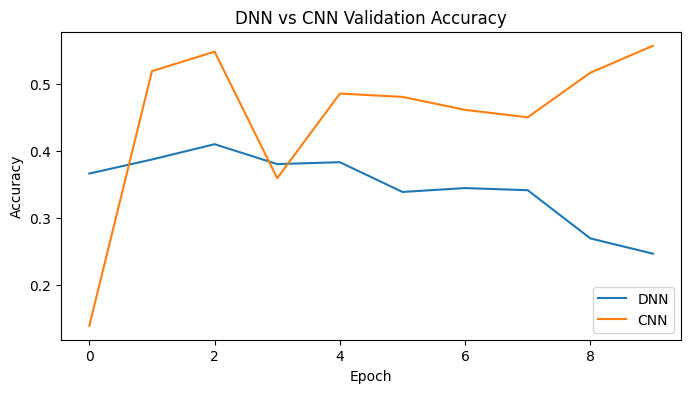

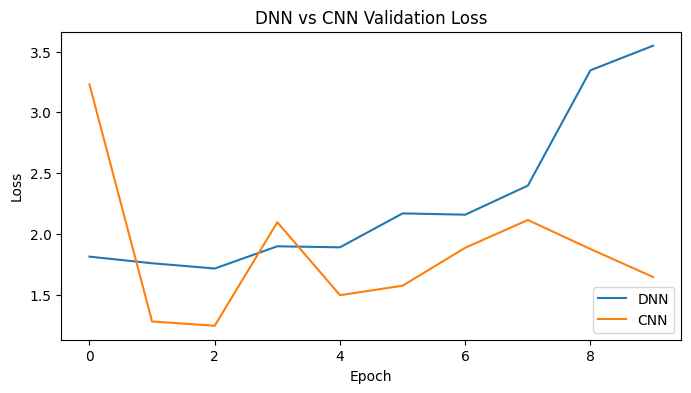

In [15]:

# 성능 비교표
comparison = pd.DataFrame({
    "Model": ["DNN", "CNN"],
    "Test Accuracy": [dnn_acc, cnn_acc],
    "Test Loss": [dnn_loss, cnn_loss],
    "Total Parameters": [
        dnn_model.count_params(),
        cnn_model.count_params()
    ]
})

print("===== Model Comparison =====")
print(comparison.to_string(index=False))

# 검증 정확도 비교
plt.figure(figsize=(8, 4))

plt.plot(
    history_dnn.history["val_accuracy"],
    label="DNN"
)
plt.plot(
    history_cnn.history["val_accuracy"],
    label="CNN"
)

plt.title("DNN vs CNN Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 검증 손실 비교
plt.figure(figsize=(8, 4))

plt.plot(
    history_dnn.history["val_loss"],
    label="DNN"
)
plt.plot(
    history_cnn.history["val_loss"],
    label="CNN"
)

plt.title("DNN vs CNN Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

CIFAR-10 데이터에서 CNN의 테스트 정확도는 55.99%로 DNN의 24.21%보다 높았으며, 손실값도 더 낮게 나타났다. 검증 그래프에서도 CNN은 전반적으로 높은 정확도를 보인 반면, DNN은 학습 후반에 정확도가 감소하고 손실이 증가하는 경향을 보였다. 따라서 CNN이 더 적은 모수로 높은 이미지 분류 성능을 보였음을 확인할 수 있었다.

### #2.4) DNN과 CNN 전체 모수 개수 계산

In [17]:
# 전체 모수 개수
print("===== Total Parameters =====")
print("DNN:", dnn_model.count_params())
print("CNN:", cnn_model.count_params())

# DNN 층별 모수 개수
print("\n===== DNN Parameters by Layer =====")
for layer in dnn_model.layers:
    print(layer.name, ":", layer.count_params())

# CNN 층별 모수 개수
print("\n===== CNN Parameters by Layer =====")
for layer in cnn_model.layers:
    print(layer.name, ":", layer.count_params())

===== Total Parameters =====
DNN: 1056266
CNN: 156842

===== DNN Parameters by Layer =====
input_layer_7 : 0
flatten_4 : 0
dense_30 : 786432
batch_normalization_44 : 1024
activation_41 : 0
dense_31 : 65536
batch_normalization_45 : 1024
activation_42 : 0
dense_32 : 65536
batch_normalization_46 : 1024
add_17 : 0
activation_43 : 0
dense_33 : 65536
batch_normalization_47 : 1024
activation_44 : 0
dense_34 : 65536
batch_normalization_48 : 1024
add_18 : 0
activation_45 : 0
dense_35 : 2570

===== CNN Parameters by Layer =====
input_layer_6 : 0
conv2d_16 : 864
batch_normalization_36 : 128
activation_34 : 0
conv2d_17 : 9216
batch_normalization_37 : 128
activation_35 : 0
conv2d_18 : 9216
batch_normalization_38 : 128
add_14 : 0
activation_36 : 0
conv2d_19 : 18432
batch_normalization_39 : 256
activation_37 : 0
conv2d_21 : 2048
conv2d_20 : 36864
batch_normalization_41 : 256
batch_normalization_40 : 256
add_15 : 0
activation_38 : 0
conv2d_22 : 36864
batch_normalization_42 : 256
activation_39 : 0
conv

DNN과 CNN의 전체 모수 개수를 계산한 결과, DNN은 1,056,266개, CNN은 156,842개로 나타났다.

DNN: 786,432 + 262,144 + 2,570 + 5,120 = 1,056,266개

CNN: 150,368 + 4,810 + 1,664 = 156,842개

CNN은 DNN보다 모수 개수가 적으면서도 더 높은 분류 정확도를 보였다. 이를 통해 이번 실험에서는 CNN이 더 적은 모수로 효과적인 이미지 분류 성능을 나타냈음을 확인할 수 있었다.

### #3.1)

In [18]:
import pandas as pd
import numpy as np

from google.colab import files

# 파일 업로드
uploaded = files.upload()

# 데이터 불러오기
df = pd.read_csv("bike.csv")

# 데이터 구조 확인
print("===== Data Shape =====")
print(df.shape)

print("\n===== Columns =====")
print(df.columns.tolist())

print("\n===== First 5 Rows =====")
print(df.head())

print("\n===== Data Types =====")
print(df.dtypes)

print("\n===== Missing Values =====")
print(df.isnull().sum())


Saving bike.csv to bike.csv
===== Data Shape =====
(8645, 16)

===== Columns =====
['Unnamed: 0', 'season', 'mnth', 'day', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'bikers']

===== First 5 Rows =====
   Unnamed: 0  season mnth  day  hr  holiday  weekday  workingday weathersit  \
0           1       1  Jan    1   0        0        6           0      clear   
1           2       1  Jan    1   1        0        6           0      clear   
2           3       1  Jan    1   2        0        6           0      clear   
3           4       1  Jan    1   3        0        6           0      clear   
4           5       1  Jan    1   4        0        6           0      clear   

   temp   atemp   hum  windspeed  casual  registered  bikers  
0  0.24  0.2879  0.81        0.0       3          13      16  
1  0.22  0.2727  0.80        0.0       8          32      40  
2  0.22  0.2727  0.80        0.0       5          27  

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

tf.keras.utils.set_random_seed(42)

# 입력변수와 목표변수
features = ["mnth", "hr", "workingday", "weathersit", "temp"]

X = df[features].copy()
y = df["bikers"].values

# 범주형 변수 처리
X["hr"] = X["hr"].astype(str)
X["workingday"] = X["workingday"].astype(str)

categorical_features = [
    "mnth", "hr", "workingday", "weathersit"
]
numeric_features = ["temp"]

# 학습·테스트 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 전처리
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore",
                          sparse_output=False),
     categorical_features),
    ("num", StandardScaler(), numeric_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

X_train_processed = X_train_processed.astype("float32")
X_test_processed = X_test_processed.astype("float32")

print("Train:", X_train_processed.shape)
print("Test:", X_test_processed.shape)
print("Target:", y_train.shape, y_test.shape)


Train: (6916, 42)
Test: (1729, 42)
Target: (6916,) (1729,)


In [20]:
# DNN 모델 학습 및 평가
# DNN 모델 생성
dnn_model = models.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

dnn_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_dnn = dnn_model.fit(
    X_train_processed, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

# 예측
dnn_pred = dnn_model.predict(
    X_test_processed, verbose=0
).ravel()

# 성능 평가
dnn_rmse = np.sqrt(mean_squared_error(y_test, dnn_pred))
dnn_mae = mean_absolute_error(y_test, dnn_pred)

print("===== DNN Results =====")
print("RMSE:", dnn_rmse)
print("MAE:", dnn_mae)

Epoch 1/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 36719.3711 - mae: 139.4924 - val_loss: 36250.3945 - val_mae: 134.1615
Epoch 2/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 25717.5703 - mae: 111.4478 - val_loss: 17547.7305 - val_mae: 91.2340
Epoch 3/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11988.5459 - mae: 81.1097 - val_loss: 11194.1670 - val_mae: 80.8581
Epoch 4/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9296.9170 - mae: 72.6494 - val_loss: 9245.9248 - val_mae: 71.5297
Epoch 5/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 7782.3530 - mae: 65.0844 - val_loss: 7751.6294 - val_mae: 64.2257
Epoch 6/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 6631.9033 - mae: 59.2295 - val_loss: 6628.8130 - val_mae: 58.3352
Epoch 7/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5837.5396 - mae: 54.9727 - val_loss: 5910.9214 - val_mae: 54.4854
Epoch 8/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 5375.9004 - mae: 52.3311 - val_loss: 5508.0522 - val_mae: 52.0471

Bikeshare 데이터에 DNN 모델을 적용한 결과, 테스트 RMSE는 50.8313, MAE는 33.4472로 나타났다. 학습이 진행됨에 따라 학습 손실과 검증 손실이 지속적으로 감소하여, 뚜렷한 과적합 없이 모델이 학습되는 것을 확인할 수 있었다.

In [21]:
# 1D-CNN 모델 학습 및 평가
# CNN 입력 형태 변환
X_train_cnn = X_train_processed.reshape(
    X_train_processed.shape[0],
    X_train_processed.shape[1],
    1
)

X_test_cnn = X_test_processed.reshape(
    X_test_processed.shape[0],
    X_test_processed.shape[1],
    1
)

# 1D-CNN 모델 생성
cnn_model = models.Sequential([
    layers.Input(shape=(X_train_processed.shape[1], 1)),
    layers.Conv1D(32, kernel_size=3,
                  padding="same", activation="relu"),
    layers.Conv1D(64, kernel_size=3,
                  padding="same", activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

cnn_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

history_cnn = cnn_model.fit(
    X_train_cnn, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

# 예측
cnn_pred = cnn_model.predict(
    X_test_cnn, verbose=0
).ravel()

# 성능 평가
cnn_rmse = np.sqrt(mean_squared_error(y_test, cnn_pred))
cnn_mae = mean_absolute_error(y_test, cnn_pred)

print("===== 1D-CNN Results =====")
print("RMSE:", cnn_rmse)
print("MAE:", cnn_mae)


Epoch 1/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 34812.2852 - mae: 134.4658 - val_loss: 27308.4707 - val_mae: 114.4205
Epoch 2/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 18105.7637 - mae: 103.8050 - val_loss: 18632.4785 - val_mae: 109.1109
Epoch 3/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 16977.6914 - mae: 103.5595 - val_loss: 18570.5664 - val_mae: 109.3353
Epoch 4/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 16916.3730 - mae: 103.3722 - val_loss: 18508.4863 - val_mae: 109.2373
Epoch 5/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 16852.1133 - mae: 103.1622 - val_loss: 18448.0039 - val_mae: 109.1366
Epoch 6/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 16792.7832 - mae: 102.9705 - val_loss: 18394.1133 - val_mae: 109.0351
Epoch 7/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 16737.9648 - mae: 102.7919 - val_loss: 18341.2129 - val_mae: 108.8988
Epoch 8/30
87/87 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 16684.3652 - mae: 102.6144 - val_loss: 182

Bikeshare 데이터에 1D-CNN 모델을 적용한 결과, 테스트 RMSE는 121.3795, MAE는 96.0077로 나타났다. 두 평가 지표 모두 DNN보다 높게 나타나, 이번 실험에서는 1D-CNN의 예측 성능이 상대적으로 낮음을 확인할 수 있었다.

In [22]:
# Random Forest 모델 학습 및 평가
# RF 모델 생성 및 학습
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

# 예측
rf_pred = rf_model.predict(X_test_processed)

# 성능 평가
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test, rf_pred)

print("===== Random Forest Results =====")
print("RMSE:", rf_rmse)
print("MAE:", rf_mae)


===== Random Forest Results =====
RMSE: 58.65231914356019
MAE: 38.52716885175151


Bikeshare 데이터에 Random Forest 모델을 적용한 결과, 테스트 RMSE는 58.6523, MAE는 38.5272로 나타났다. 이는 실제 자전거 대여량과 예측값 사이의 평균 절대 오차가 약 38.53대이며, 큰 예측 오차에 더 큰 가중치를 부여하는 RMSE는 약 58.65임을 의미한다.

===== Model Comparison =====
        Model       RMSE       MAE
          DNN  50.831324 33.447189
       1D-CNN 121.379481 96.007706
Random Forest  58.652319 38.527169


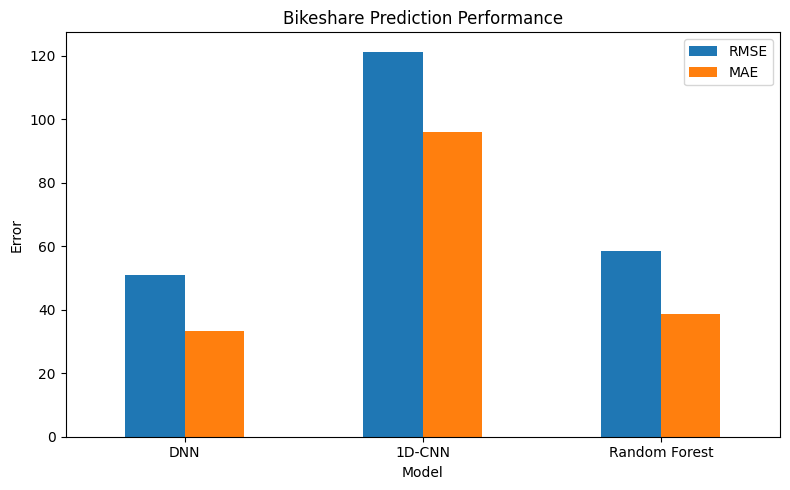

In [23]:
# 세 모델의 예측 성능 비교
results = pd.DataFrame({
    "Model": ["DNN", "1D-CNN", "Random Forest"],
    "RMSE": [dnn_rmse, cnn_rmse, rf_rmse],
    "MAE": [dnn_mae, cnn_mae, rf_mae]
})

print("===== Model Comparison =====")
print(results.to_string(index=False))

# 성능 비교 그래프
results.set_index("Model")[["RMSE", "MAE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Bikeshare Prediction Performance")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


DNN, 1D-CNN, Random Forest 모델의 예측 성능을 RMSE와 MAE를 기준으로 비교하였다. 분석 결과, DNN은 RMSE 50.8313, MAE 33.4472로 가장 낮은 예측 오차를 보였으며, Random Forest는 RMSE 58.6523, MAE 38.5272로 그다음으로 우수한 성능을 나타냈다. 반면 1D-CNN은 RMSE 121.3795, MAE 96.0077로 가장 높은 예측 오차를 보였다.

따라서 본 실험에서는 DNN, Random Forest, 1D-CNN 순으로 예측 성능이 우수한 것으로 나타났다.

### #3.2)

In [24]:
# PFI
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
import pandas as pd
import numpy as np

# 기존 학습 모델의 예측 함수를 정의
def predict_dnn(X):
    X_p = preprocessor.transform(X).astype("float32")
    return dnn_model.predict(X_p, verbose=0).ravel()

def predict_cnn(X):
    X_p = preprocessor.transform(X).astype("float32")
    X_p = X_p.reshape(X_p.shape[0], X_p.shape[1], 1)
    return cnn_model.predict(X_p, verbose=0).ravel()

def predict_rf(X):
    X_p = preprocessor.transform(X).astype("float32")
    return rf_model.predict(X_p)

# PFI 계산 함수
def calculate_pfi(predict_fn, X, y, n_repeats=5):
    rng = np.random.default_rng(42)

    baseline = mean_squared_error(y, predict_fn(X))
    importance = []

    for col in X.columns:
        scores = []

        for _ in range(n_repeats):
            X_perm = X.copy()
            X_perm[col] = rng.permutation(X_perm[col].to_numpy())

            perm_mse = mean_squared_error(
                y, predict_fn(X_perm)
            )

            scores.append(perm_mse - baseline)

        importance.append(np.mean(scores))

    return pd.Series(importance, index=X.columns)

# 세 모델의 PFI 계산
pfi_dnn = calculate_pfi(predict_dnn, X_test, y_test)
pfi_cnn = calculate_pfi(predict_cnn, X_test, y_test)
pfi_rf = calculate_pfi(predict_rf, X_test, y_test)

# 결과 정리
pfi_results = pd.DataFrame({
    "DNN": pfi_dnn,
    "1D-CNN": pfi_cnn,
    "Random Forest": pfi_rf
})

print("===== PFI Results (Increase in MSE) =====")
print(pfi_results.round(2))

===== PFI Results (Increase in MSE) =====
                 DNN   1D-CNN  Random Forest
mnth         2977.72   121.49         489.94
hr          22831.17   165.85       20165.16
workingday   3395.09   -71.76        3826.41
weathersit   1003.77    24.30         716.32
temp         2525.23  7182.85        9142.93


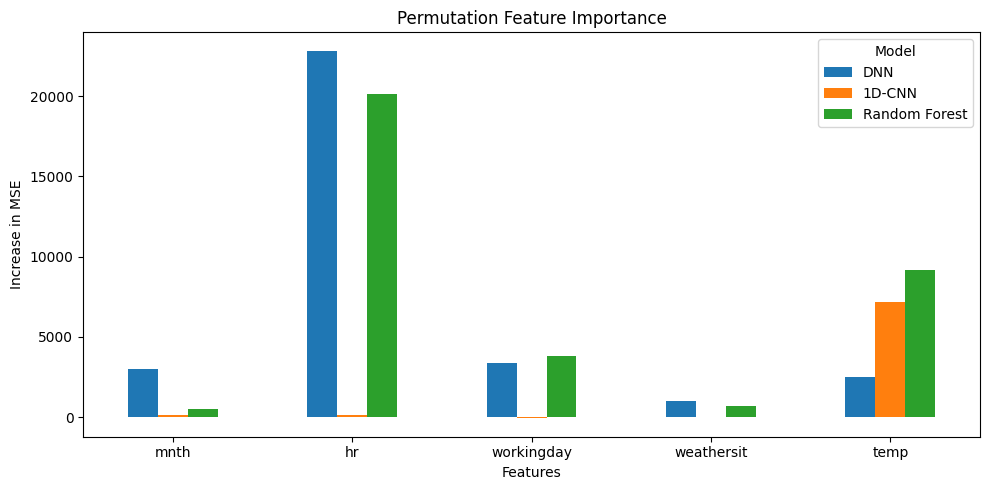

In [25]:
# PFI 시각화
import matplotlib.pyplot as plt

pfi_results.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Permutation Feature Importance")
plt.xlabel("Features")
plt.ylabel("Increase in MSE")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

PFI 시각화 결과, DNN과 Random Forest에서는 hr(시간)의 변수 중요도가 가장 높게 나타났으며, 1D-CNN에서는 temp(기온)의 중요도가 가장 높게 나타났다. 이를 통해 DNN과 Random Forest는 시간 정보를, 1D-CNN은 기온 정보를 상대적으로 중요하게 활용하고 있음을 확인할 수 있었다.

따라서 모델에 따라 자전거 대여량 예측에 활용하는 주요 변수에 차이가 있는 것으로 나타났다.

In [26]:
# SHAP
import shap
import numpy as np
import pandas as pd

# 계산 시간을 줄이기 위해 일부 데이터 사용
X_background = X_train.sample(n=50, random_state=42)
X_shap = X_test.sample(n=100, random_state=42)

print("SHAP Background:", X_background.shape)
print("SHAP Test:", X_shap.shape)
print("Features:", X_shap.columns.tolist())
print("SHAP Version:", shap.__version__)

SHAP Background: (50, 5)
SHAP Test: (100, 5)
Features: ['mnth', 'hr', 'workingday', 'weathersit', 'temp']
SHAP Version: 0.54.1


In [28]:
# 범주형 변수를 숫자로 변환하기 위한 코드
category_maps = {}

X_background_num = X_background.copy()
X_shap_num = X_shap.copy()

categorical_cols = [
    "mnth", "hr", "workingday", "weathersit"
]

for col in categorical_cols:
    categories = X_train[col].unique()
    category_maps[col] = {
        value: i for i, value in enumerate(categories)
    }

    X_background_num[col] = X_background[col].map(
        category_maps[col]
    )
    X_shap_num[col] = X_shap[col].map(
        category_maps[col]
    )

# 숫자 데이터를 원래 범주형 데이터로 복원
def restore_categories(X_array):
    X_df = pd.DataFrame(
        X_array,
        columns=X_shap.columns
    )

    for col in categorical_cols:
        inverse_map = {
            v: k for k, v in category_maps[col].items()
        }

        X_df[col] = (
            X_df[col]
            .round()
            .astype(int)
            .map(inverse_map)
        )

    return X_df

# SHAP에서 사용할 DNN 예측 함수
def predict_dnn_shap(X_array):
    X_original = restore_categories(X_array)
    return predict_dnn(X_original)

# SHAP Explainer 생성
explainer_dnn = shap.Explainer(
    predict_dnn_shap,
    shap.maskers.Independent(
        X_background_num.to_numpy(dtype=float)
    ),
    algorithm="permutation"
)

# SHAP 값 계산
shap_values_dnn = explainer_dnn(
    X_shap_num.to_numpy(dtype=float),
    max_evals=101
)

# 변수별 평균 절대 SHAP 값
shap_importance_dnn = pd.Series(
    np.abs(shap_values_dnn.values).mean(axis=0),
    index=X_shap.columns
).sort_values(ascending=False)

print("===== DNN SHAP Importance =====")
print(shap_importance_dnn.round(4))

PermutationExplainer explainer: 101it [01:40,  1.04s/it]

===== DNN SHAP Importance =====
hr            64.7972
mnth          27.0807
temp          21.1256
workingday    13.3283
weathersit    11.3473
dtype: float64


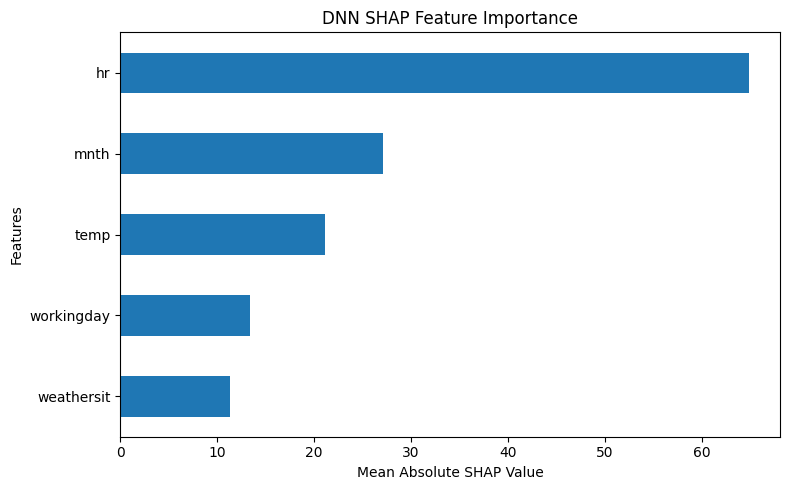

In [29]:
# DNN SHAP 변수 중요도 시각화
shap_importance_dnn.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("DNN SHAP Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

DNN 모델에 SHAP을 적용하여 변수 중요도를 분석한 결과, hr(시간)의 평균 절대 SHAP 값이 64.7972로 가장 높게 나타났다. 다음으로 mnth(월) 27.0807, temp(기온) 21.1256, workingday(근무일 여부) 13.3283, weathersit(날씨 상태) 11.3473 순으로 나타났다.

따라서 DNN 모델은 자전거 대여량을 예측할 때 시간 정보를 가장 중요하게 활용하는 것으로 확인되었다.

In [30]:
# SHAP에서 사용할 1D-CNN 예측 함수
def predict_cnn_shap(X_array):
    X_original = restore_categories(X_array)
    return predict_cnn(X_original)

# 1D-CNN SHAP Explainer 생성
explainer_cnn = shap.Explainer(
    predict_cnn_shap,
    shap.maskers.Independent(
        X_background_num.to_numpy(dtype=float)
    ),
    algorithm="permutation"
)

# SHAP 값 계산
shap_values_cnn = explainer_cnn(
    X_shap_num.to_numpy(dtype=float),
    max_evals=101
)

# 변수별 평균 절대 SHAP 값
shap_importance_cnn = pd.Series(
    np.abs(shap_values_cnn.values).mean(axis=0),
    index=X_shap.columns
).sort_values(ascending=False)

print("===== 1D-CNN SHAP Importance =====")
print(shap_importance_cnn.round(4))

PermutationExplainer explainer: 101it [01:41,  1.07s/it]

===== 1D-CNN SHAP Importance =====
temp          47.8270
mnth          10.1106
hr             3.3700
workingday     2.9616
weathersit     1.9378
dtype: float64


1D-CNN 모델에 SHAP을 적용하여 변수 중요도를 분석한 결과, temp(기온)의 평균 절대 SHAP 값이 47.8270으로 가장 높게 나타났다. 다음으로 mnth(월) 10.1106, hr(시간) 3.3700, workingday(근무일 여부) 2.9616, weathersit(날씨 상태) 1.9378 순으로 나타났다.

특히 temp의 중요도가 다른 변수들보다 크게 나타나, 1D-CNN 모델은 자전거 대여량 예측에서 기온 정보를 가장 중요하게 활용하는 것으로 확인되었다.

In [31]:
# SHAP에서 사용할 Random Forest 예측 함수
def predict_rf_shap(X_array):
    X_original = restore_categories(X_array)
    return predict_rf(X_original)

# Random Forest SHAP Explainer 생성
explainer_rf = shap.Explainer(
    predict_rf_shap,
    shap.maskers.Independent(
        X_background_num.to_numpy(dtype=float)
    ),
    algorithm="permutation"
)

# SHAP 값 계산
shap_values_rf = explainer_rf(
    X_shap_num.to_numpy(dtype=float),
    max_evals=101
)

# 변수별 평균 절대 SHAP 값
shap_importance_rf = pd.Series(
    np.abs(shap_values_rf.values).mean(axis=0),
    index=X_shap.columns
).sort_values(ascending=False)

print("===== Random Forest SHAP Importance =====")
print(shap_importance_rf.round(4))

PermutationExplainer explainer: 101it [01:05,  1.33it/s]

===== Random Forest SHAP Importance =====
hr            53.6727
temp          43.3708
workingday    11.9401
weathersit     7.9065
mnth           3.8375
dtype: float64


Random Forest 모델의 SHAP 분석 결과, hr(시간)의 중요도가 53.6727로 가장 높았으며, temp(기온)가 43.3708로 그다음으로 나타났다. 반면 나머지 변수들의 중요도는 상대적으로 낮았다.

따라서 Random Forest는 자전거 대여량 예측에서 시간과 기온 정보를 중요하게 활용하는 것으로 나타났다.

===== SHAP Comparison =====
              DNN  1D-CNN  Random Forest
hr          64.80    3.37          53.67
mnth        27.08   10.11           3.84
temp        21.13   47.83          43.37
weathersit  11.35    1.94           7.91
workingday  13.33    2.96          11.94


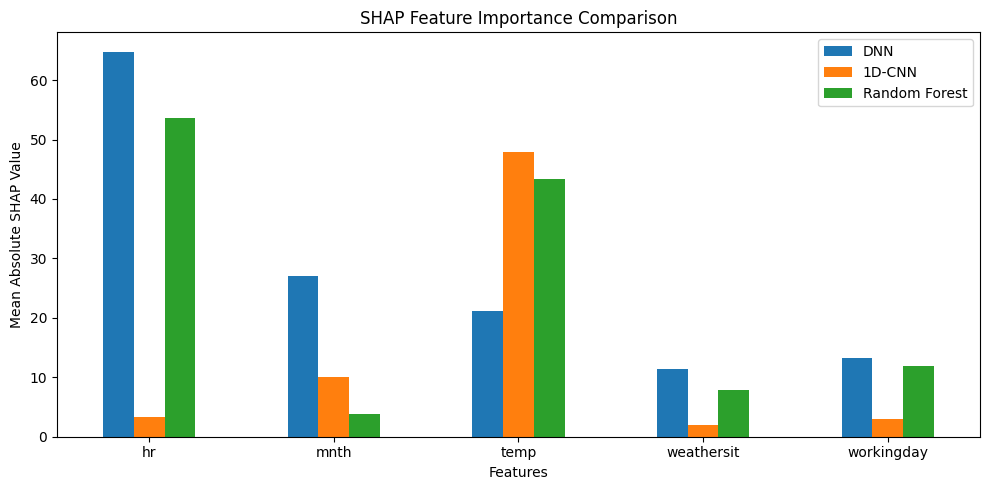

In [32]:
# 최종 비교
# 세 모델의 SHAP 결과 비교
shap_results = pd.DataFrame({
    "DNN": shap_importance_dnn,
    "1D-CNN": shap_importance_cnn,
    "Random Forest": shap_importance_rf
})

print("===== SHAP Comparison =====")
print(shap_results.round(2))

# SHAP 중요도 비교 그래프
shap_results.plot(kind="bar", figsize=(10, 5))

plt.title("SHAP Feature Importance Comparison")
plt.xlabel("Features")
plt.ylabel("Mean Absolute SHAP Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

 => PFI와 SHAP을 이용하여 DNN, 1D-CNN, Random Forest 모델의 변수 중요도를 비교하였다. 분석 결과, DNN과 Random Forest에서는 두 방법 모두 hr(시간)이 가장 중요한 변수로 나타났으며, 1D-CNN에서는 temp(기온)의 중요도가 가장 높았다.

두 분석 방법에서 각 모델의 가장 중요한 변수는 일치했지만, 나머지 변수들의 중요도 순위에는 일부 차이가 있었다. 따라서 모델에 따라 중요하게 활용하는 변수가 다르며, PFI와 SHAP의 평가 방식에 따라서도 변수 중요도에 차이가 나타날 수 있음을 확인하였다
두 분석 방법에서 각 모델의 가장 중요한 변수는 일치했지만, 나머지 변수들의 중요도 순위에는 일부 차이가 있었다. 따라서 모델에 따라 중요하게 활용하는 변수가 다르며, PFI와 SHAP의 평가 방식에 따라서도 변수 중요도에 차이가 나타날 수 있음을 확인하였다